[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch20_07_SKOOL_LSTM_Sequence_Predictor_for_Kids.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 20: LSTM and GRU** (Part IV: Meaning and Memory). This is the kids' course edition of the lab, kept for comparison.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=20](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=20)
* The video course this book grew from: [www.aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# 🧠 LSTM: Teaching AI to Remember!
## A Fun Journey into Sequence Prediction

---

### 🤔 What's the Next Number?

Can you guess the next number?

- `1, 2, 3, 4, ?` → Easy! It's **5**
- `2, 4, 6, 8, ?` → It's **10** (counting by 2s)
- `1, 1, 2, 3, 5, ?` → It's **8** (Fibonacci: add the last two!)

**How did you know?** Because you **REMEMBERED** the pattern!

Regular neural networks forget things quickly. But **LSTM** (Long Short-Term Memory) networks are special - they can **remember** patterns, just like you!

---

### 🎯 What We'll Learn:
1. Why remembering is important for sequences
2. How LSTM "remembers" like a student with a notebook
3. Build an LSTM to predict number sequences
4. Test it with your own patterns!

---

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **The test now tells the truth.** The message "The LSTM learned to count by 1s!" was printed whatever the numbers said. It now counts how many rows were right, explains the row outside the training range, and compares the LSTM with a simple rule (last number + step), which is exact. (The comment on the last test row also said "should predict 100"; it is 110.)
> * **LSTMs use their default tanh.** All 5 LSTM layers had `activation='relu'`, which makes the cell's memory unbounded and training fragile (and switches off the fast GPU kernel). The `Dense(25)` stays, with a suggested experiment to remove it.
> * The custom example sequence was labelled "Fibonacci!"; 1, 2, 4, 7, 11, 16... adds 1, then 2, then 3: the lazy caterer numbers. "More training = better predictions" became "test fairly", "predict stock prices" became a forecasting example LSTMs really are used for, and the closing tip names the real Step 9 settings.
> * `keras.utils.set_random_seed(42)` makes runs repeatable; training prints one line per epoch; emoji removed from 20 plot titles (Matplotlib cannot draw them).

## 📖 The Story of LSTM: A Student with a Special Notebook

Imagine you're in math class, and the teacher writes numbers on the board one at a time:

```
Teacher: "2"
Teacher: "4"
Teacher: "6"
Teacher: "What comes next?"
```

### 🧒 A Student WITHOUT Memory (Regular Neural Network)
- Only sees the LAST number: "6"
- Thinks: "Hmm, 6... maybe 7? Or 100? I don't know!"
- **Problem**: Can't see the pattern because they forgot the earlier numbers!

### 📓 A Student WITH a Notebook (LSTM)
- Writes down EVERY number in their notebook
- Looks at their notes: "2, 4, 6... I see! Adding 2 each time!"
- Confidently answers: "**8!**"

---

## 🔑 LSTM's Three Magic Gates

LSTM has THREE special "gates" (like doors) that control memory:

| Gate | What It Does | Analogy |
|------|-------------|----------|
| 🚪 **Forget Gate** | Decides what OLD info to throw away | "Do I still need to remember my breakfast?" |
| 📥 **Input Gate** | Decides what NEW info to remember | "This number looks important, let me write it down!" |
| 📤 **Output Gate** | Decides what to share/answer | "Based on my notes, the answer is..." |

---

## 📦 Step 1: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
keras.utils.set_random_seed(42)   # Python, NumPy and TensorFlow in one call: the same run every time

print("✅ Libraries loaded!")
print(f"TensorFlow: {tf.__version__}")
print(f"Keras: {keras.__version__}")

✅ Libraries loaded!
TensorFlow: 2.21.0
Keras: 3.14.1


---
## 🔢 Step 2: Create Number Sequences

Let's create different patterns for our LSTM to learn!

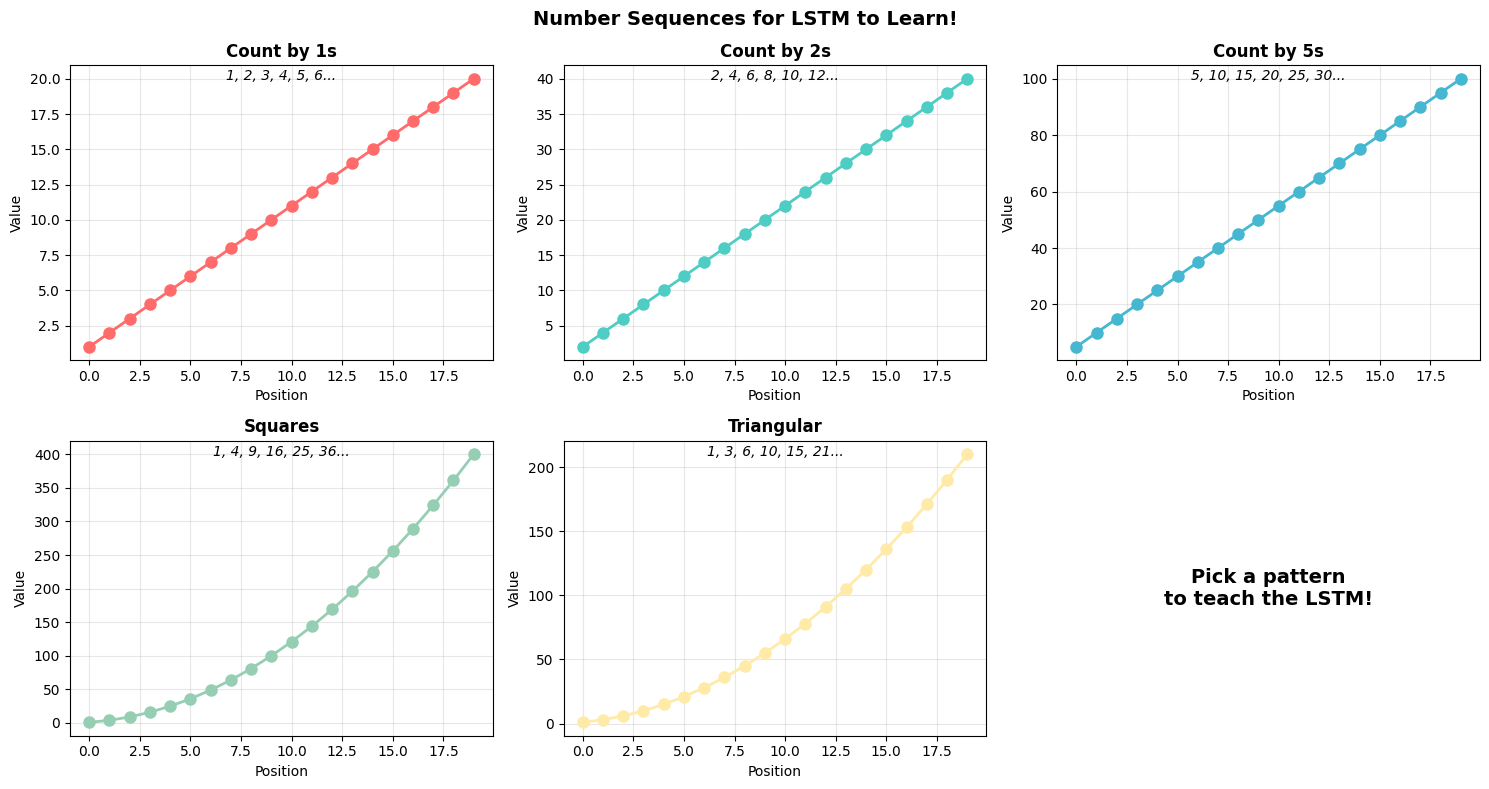


💡 Each sequence has a PATTERN. Can you spot them all?


In [2]:
# ============================================================================
# 🔢 CREATE FUN NUMBER SEQUENCES
# ============================================================================

def create_counting_sequence(start=0, step=1, length=100):
    """Create a counting sequence: 0,1,2,3... or 0,2,4,6..."""
    return np.array([start + i * step for i in range(length)])

def create_fibonacci_sequence(length=100):
    """Create Fibonacci: 1,1,2,3,5,8,13..."""
    seq = [1, 1]
    for i in range(length - 2):
        seq.append(seq[-1] + seq[-2])
    return np.array(seq)

def create_square_sequence(length=100):
    """Create squares: 1,4,9,16,25..."""
    return np.array([(i+1)**2 for i in range(length)])

def create_triangular_sequence(length=100):
    """Create triangular numbers: 1,3,6,10,15..."""
    return np.array([(i+1)*(i+2)//2 for i in range(length)])

# Let's visualize our sequences!
sequences = {
    'Count by 1s': create_counting_sequence(1, 1, 20),
    'Count by 2s': create_counting_sequence(2, 2, 20),
    'Count by 5s': create_counting_sequence(5, 5, 20),
    'Squares': create_square_sequence(20),
    'Triangular': create_triangular_sequence(20),
}

# Plot sequences
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']

for idx, (name, seq) in enumerate(sequences.items()):
    axes[idx].plot(seq, 'o-', color=colors[idx], linewidth=2, markersize=8)
    axes[idx].set_title(f'{name}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Position')
    axes[idx].set_ylabel('Value')
    axes[idx].grid(True, alpha=0.3)

    # Show first few numbers
    preview = ', '.join(map(str, seq[:6])) + '...'
    axes[idx].text(0.5, 0.95, preview, transform=axes[idx].transAxes,
                   ha='center', fontsize=10, style='italic')

# Hide empty subplot
axes[5].axis('off')
axes[5].text(0.5, 0.5, 'Pick a pattern\nto teach the LSTM!',
             ha='center', va='center', fontsize=14, fontweight='bold',
             transform=axes[5].transAxes)

plt.suptitle('Number Sequences for LSTM to Learn!', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Each sequence has a PATTERN. Can you spot them all?")

---
## 📝 Step 3: Prepare Data for LSTM

LSTM needs data in a special format:
- **Input**: A window of numbers (e.g., `[1, 2, 3]`)
- **Output**: The next number (e.g., `4`)

It's like showing the LSTM a few numbers and asking: "What comes next?"

In [3]:
# ============================================================================
# 📝 PREPARE DATA FOR LSTM
# ============================================================================

def prepare_sequences(data, window_size=5):
    """
    Convert a sequence into input-output pairs for LSTM.

    Example with window_size=3:
    [1,2,3,4,5,6] becomes:
        Input: [1,2,3] -> Output: 4
        Input: [2,3,4] -> Output: 5
        Input: [3,4,5] -> Output: 6
    """
    X, y = [], []

    for i in range(len(data) - window_size):
        # Input: window_size numbers
        X.append(data[i:i+window_size])
        # Output: the next number
        y.append(data[i+window_size])

    X = np.array(X)
    y = np.array(y)

    # Reshape X for LSTM: (samples, timesteps, features)
    X = X.reshape((X.shape[0], X.shape[1], 1))

    return X, y


# Let's use "Count by 1s" as our first example
# We'll use numbers 1 to 100
sequence = create_counting_sequence(1, 1, 100)
print(f"📊 Our sequence: {sequence[:10]}... (100 numbers total)")

# Normalize to 0-1 range (helps LSTM learn better)
max_value = sequence.max()
sequence_normalized = sequence / max_value
print(f"📊 Normalized: {sequence_normalized[:5]}...")

# Prepare data with window size of 5
# (Show 5 numbers, predict the 6th)
WINDOW_SIZE = 5
X, y = prepare_sequences(sequence_normalized, WINDOW_SIZE)

print(f"\n✅ Data prepared!")
print(f"   X shape: {X.shape} → {X.shape[0]} samples, {X.shape[1]} timesteps, {X.shape[2]} feature")
print(f"   y shape: {y.shape} → {y.shape[0]} targets")

# Show an example
print(f"\n📝 Example:")
example_input = X[0].flatten() * max_value
example_output = y[0] * max_value
print(f"   Input:  {example_input.astype(int)} → Output: {int(example_output)}")
print(f"   (Given [1,2,3,4,5], predict 6!)")

📊 Our sequence: [ 1  2  3  4  5  6  7  8  9 10]... (100 numbers total)
📊 Normalized: [0.01 0.02 0.03 0.04 0.05]...

✅ Data prepared!
   X shape: (95, 5, 1) → 95 samples, 5 timesteps, 1 feature
   y shape: (95,) → 95 targets

📝 Example:
   Input:  [1 2 3 4 5] → Output: 6
   (Given [1,2,3,4,5], predict 6!)


### 👀 Let's Visualize How Data is Prepared

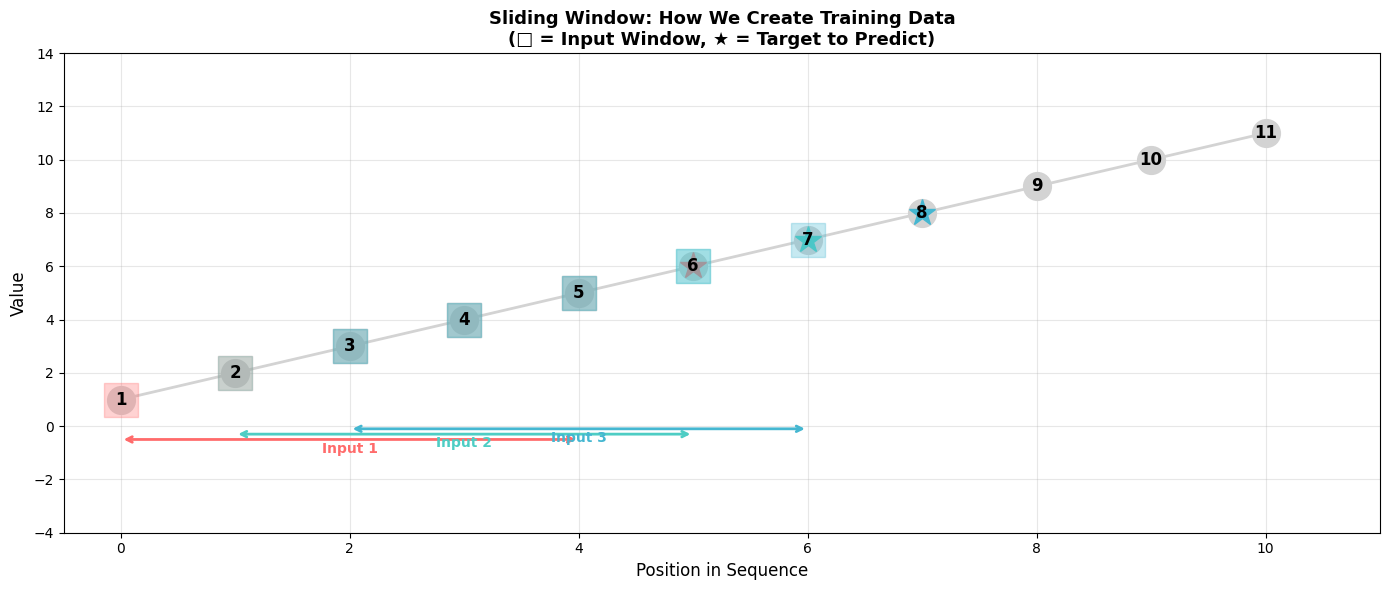


💡 The window SLIDES across the sequence:
   Window 1: [1,2,3,4,5] → predict 6
   Window 2: [2,3,4,5,6] → predict 7
   Window 3: [3,4,5,6,7] → predict 8
   ...and so on!


In [4]:
# ============================================================================
# 👀 VISUALIZE DATA PREPARATION
# ============================================================================

fig, ax = plt.subplots(figsize=(14, 6))

# Show the sliding window concept
full_seq = list(range(1, 12))  # 1 to 11

# Plot full sequence
ax.plot(range(len(full_seq)), full_seq, 'o-', color='lightgray',
        markersize=20, linewidth=2, label='Full Sequence')

# Add number labels
for i, num in enumerate(full_seq):
    ax.text(i, num, str(num), ha='center', va='center', fontsize=12, fontweight='bold')

# Show windows
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
for w, color in enumerate(colors):
    start = w
    # Input window
    ax.plot(range(start, start+5), full_seq[start:start+5], 's',
            color=color, markersize=25, alpha=0.3, label=f'Window {w+1} Input')
    # Target
    ax.plot(start+5, full_seq[start+5], '*', color=color, markersize=20,
            label=f'Window {w+1} Target')

    # Draw bracket
    bracket_y = full_seq[start] - 1.5 - w*0.8
    ax.annotate('', xy=(start, bracket_y), xytext=(start+4, bracket_y),
                arrowprops=dict(arrowstyle='<->', color=color, lw=2))
    ax.text(start+2, bracket_y-0.5, f'Input {w+1}', ha='center', color=color, fontweight='bold')

ax.set_xlim(-0.5, 11)
ax.set_ylim(-4, 14)
ax.set_xlabel('Position in Sequence', fontsize=12)
ax.set_ylabel('Value', fontsize=12)
ax.set_title('Sliding Window: How We Create Training Data\n'
             '(□ = Input Window, ★ = Target to Predict)', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 The window SLIDES across the sequence:")
print("   Window 1: [1,2,3,4,5] → predict 6")
print("   Window 2: [2,3,4,5,6] → predict 7")
print("   Window 3: [3,4,5,6,7] → predict 8")
print("   ...and so on!")

---
## 🏗️ Step 4: Build the LSTM Model

Now let's build our LSTM! Think of it as creating a student with a really good memory.

In [5]:
# ============================================================================
# 🏗️ BUILD LSTM MODEL (Using Functional API for Keras 3.x compatibility)
# ============================================================================

# Define input
inputs = keras.Input(shape=(WINDOW_SIZE, 1), name='input_sequence')

# LSTM Layer - The "memory" of our network!
# 50 units = 50 different things it can remember
# (We keep the LSTM's own tanh activation: it keeps the memory between -1 and 1, which keeps training stable)
x = layers.LSTM(50, name='lstm_memory', return_sequences=False)(inputs)

# Dense layer to process the memory
# (Experiment: delete this layer. Does the model still learn to count? It has only 76 examples to learn from!)
x = layers.Dense(25, activation='relu', name='thinking_layer')(x)

# Output layer - predicts ONE number
outputs = layers.Dense(1, name='prediction')(x)

# Create model
model = keras.Model(inputs=inputs, outputs=outputs, name='LSTM_Sequence_Predictor')

# Compile
model.compile(
    optimizer='adam',
    loss='mse',  # Mean Squared Error - good for number prediction
    metrics=['mae']  # Mean Absolute Error - easier to understand
)

print("✅ LSTM Model Built!")
print("\n📊 Model Summary:")
model.summary()

✅ LSTM Model Built!

📊 Model Summary:


Model: "LSTM_Sequence_Predictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_sequence (InputLayer)     │ (None, 5, 1)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_memory (LSTM)              │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ thinking_layer (Dense)          │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

### 🧠 Understanding the LSTM Architecture

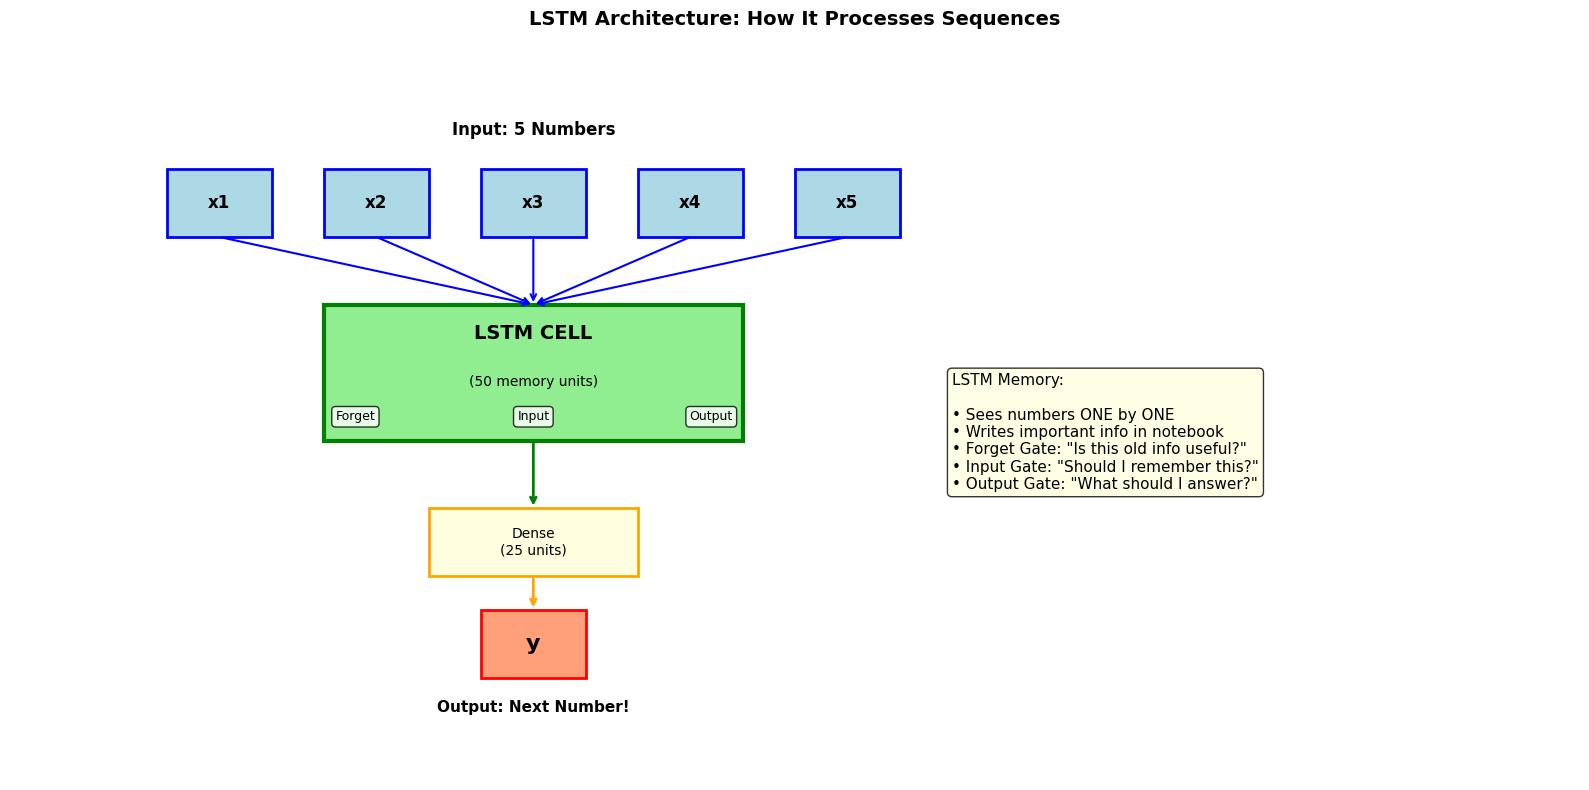

In [6]:
# ============================================================================
# 🧠 VISUALIZE LSTM ARCHITECTURE
# ============================================================================

fig, ax = plt.subplots(figsize=(16, 8))

# Draw the architecture
# Input boxes
input_y = 6
for i in range(5):
    rect = plt.Rectangle((i*1.5 + 0.5, input_y), 1, 1,
                          facecolor='lightblue', edgecolor='blue', linewidth=2)
    ax.add_patch(rect)
    ax.text(i*1.5 + 1, input_y + 0.5, f'x{i+1}', ha='center', va='center',
            fontsize=12, fontweight='bold')

ax.text(4, input_y + 1.5, 'Input: 5 Numbers', ha='center', fontsize=12, fontweight='bold')

# LSTM cell (big box with gates)
lstm_rect = plt.Rectangle((2, 3), 4, 2, facecolor='lightgreen',
                           edgecolor='green', linewidth=3)
ax.add_patch(lstm_rect)
ax.text(4, 4.5, 'LSTM CELL', ha='center', fontsize=14, fontweight='bold')
ax.text(4, 3.8, '(50 memory units)', ha='center', fontsize=10)

# Gates inside LSTM
gate_y = 3.3
gates = [('Forget', 2.3), ('Input', 4), ('Output', 5.7)]
for name, x_pos in gates:
    ax.text(x_pos, gate_y, name, ha='center', fontsize=9,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Arrows from input to LSTM
for i in range(5):
    ax.annotate('', xy=(4, 5), xytext=(i*1.5 + 1, input_y),
                arrowprops=dict(arrowstyle='->', color='blue', lw=1.5))

# Dense layer
dense_rect = plt.Rectangle((3, 1), 2, 1, facecolor='lightyellow',
                            edgecolor='orange', linewidth=2)
ax.add_patch(dense_rect)
ax.text(4, 1.5, 'Dense\n(25 units)', ha='center', va='center', fontsize=10)

# Arrow from LSTM to Dense
ax.annotate('', xy=(4, 2), xytext=(4, 3),
            arrowprops=dict(arrowstyle='->', color='green', lw=2))

# Output
output_rect = plt.Rectangle((3.5, -0.5), 1, 1, facecolor='lightsalmon',
                             edgecolor='red', linewidth=2)
ax.add_patch(output_rect)
ax.text(4, 0, 'y', ha='center', va='center', fontsize=16, fontweight='bold')
ax.text(4, -1, 'Output: Next Number!', ha='center', fontsize=11, fontweight='bold')

# Arrow from Dense to Output
ax.annotate('', xy=(4, 0.5), xytext=(4, 1),
            arrowprops=dict(arrowstyle='->', color='orange', lw=2))

# Memory illustration
ax.text(8, 4, 'LSTM Memory:\n\n'
        '• Sees numbers ONE by ONE\n'
        '• Writes important info in notebook\n'
        '• Forget Gate: "Is this old info useful?"\n'
        '• Input Gate: "Should I remember this?"\n'
        '• Output Gate: "What should I answer?"',
        fontsize=11, va='top',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

ax.set_xlim(-1, 14)
ax.set_ylim(-2, 9)
ax.axis('off')
ax.set_title('LSTM Architecture: How It Processes Sequences',
             fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 🚀 Step 5: Train the LSTM

Time to teach our LSTM the pattern!

In [7]:
# ============================================================================
# 🚀 TRAIN THE LSTM
# ============================================================================

print("🚀 Training LSTM to learn: 1, 2, 3, 4, 5, ...\n")

# Split data into training and testing
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

# Train!
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_data=(X_test, y_test),
    verbose=2   # one line per epoch
)

print("\n✅ Training complete!")

🚀 Training LSTM to learn: 1, 2, 3, 4, 5, ...

Training samples: 76
Testing samples: 19
Epoch 1/100


5/5 - 2s - 321ms/step - loss: 0.2883 - mae: 0.4735 - val_loss: 0.7647 - val_mae: 0.8727


Epoch 2/100


5/5 - 0s - 18ms/step - loss: 0.1658 - mae: 0.3536 - val_loss: 0.4590 - val_mae: 0.6761


Epoch 3/100


5/5 - 0s - 17ms/step - loss: 0.1005 - mae: 0.2698 - val_loss: 0.3031 - val_mae: 0.5492


... (191 outputs left out)

5/5 - 0s - 16ms/step - loss: 2.3687e-06 - mae: 0.0013 - val_loss: 6.3279e-05 - val_mae: 0.0076


Epoch 100/100


5/5 - 0s - 15ms/step - loss: 2.3349e-06 - mae: 0.0013 - val_loss: 6.2136e-05 - val_mae: 0.0075



✅ Training complete!


### 📈 How Well Did It Learn?

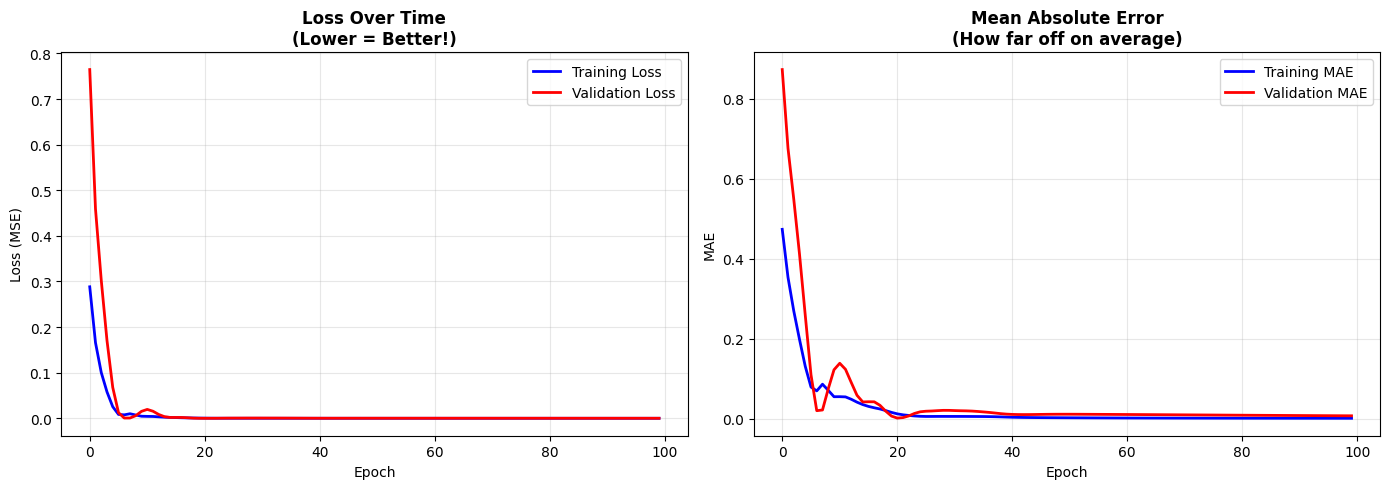


🎯 Final Performance:
   Loss: 0.000062
   MAE: 0.007503 (average error in normalized scale)


In [8]:
# ============================================================================
# 📈 PLOT TRAINING HISTORY
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history.history['loss'], 'b-', label='Training Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
axes[0].set_title('Loss Over Time\n(Lower = Better!)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MSE)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# MAE
axes[1].plot(history.history['mae'], 'b-', label='Training MAE', linewidth=2)
axes[1].plot(history.history['val_mae'], 'r-', label='Validation MAE', linewidth=2)
axes[1].set_title('Mean Absolute Error\n(How far off on average)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Final metrics
final_loss = history.history['val_loss'][-1]
final_mae = history.history['val_mae'][-1]
print(f"\n🎯 Final Performance:")
print(f"   Loss: {final_loss:.6f}")
print(f"   MAE: {final_mae:.6f} (average error in normalized scale)")

---
## 🧪 Step 6: Test the LSTM!

Let's see if our LSTM learned the pattern!

In [9]:
# ============================================================================
# 🧪 TEST THE LSTM
# ============================================================================

print("🧪 Testing LSTM Predictions!\n")

# Test on some sequences
test_sequences = [
    [1, 2, 3, 4, 5],      # Should predict 6
    [10, 11, 12, 13, 14], # Should predict 15
    [50, 51, 52, 53, 54], # Should predict 55
    [105, 106, 107, 108, 109], # Should predict 110 (bigger than anything it trained on!)
]

print("📝 Predictions:\n")
print(f"{'Input Sequence':<25} {'Expected':>10} {'Predicted':>12} {'Correct?':>10}")
print("=" * 60)
n_correct = 0

for seq in test_sequences:
    # Normalize input
    seq_norm = np.array(seq) / max_value
    seq_input = seq_norm.reshape(1, WINDOW_SIZE, 1)

    # Predict
    pred_norm = model.predict(seq_input, verbose=0)[0][0]
    pred = pred_norm * max_value

    # Expected
    expected = seq[-1] + 1

    # Check if correct (within 0.5)
    is_correct = abs(pred - expected) < 0.5
    n_correct += is_correct
    status = "✅ Yes!" if is_correct else "❌ No"

    print(f"{str(seq):<25} {expected:>10} {pred:>12.2f} {status:>10}")

print(f"\n🎯 The LSTM got {n_correct} of {len(test_sequences)} right (within 0.5).")
if n_correct == len(test_sequences):
    print("💡 The LSTM learned to count by 1s!")
else:
    print("💡 Close, but not exact. Look at the last row: 105-109 is BIGGER than any number it trained on,")
    print("   and neural networks are much better at things they have seen than at going beyond them.")
print("\n🧮 Compare with a simple rule: 'last number + (last number - the one before)'.")
print("   It gets every row EXACTLY right, even 105-109. The LSTM had to discover the rule from 76 examples;")
print("   the rule was written by someone who already knew it. Always compare your model with a simple rule!")

🧪 Testing LSTM Predictions!

📝 Predictions:

Input Sequence              Expected    Predicted   Correct?
[1, 2, 3, 4, 5]                    6         6.39     ✅ Yes!
[10, 11, 12, 13, 14]              15        14.98     ✅ Yes!


[50, 51, 52, 53, 54]              55        54.82     ✅ Yes!
[105, 106, 107, 108, 109]        110       111.60       ❌ No

🎯 The LSTM got 3 of 4 right (within 0.5).
💡 Close, but not exact. Look at the last row: 105-109 is BIGGER than any number it trained on,
   and neural networks are much better at things they have seen than at going beyond them.

🧮 Compare with a simple rule: 'last number + (last number - the one before)'.
   It gets every row EXACTLY right, even 105-109. The LSTM had to discover the rule from 76 examples;
   the rule was written by someone who already knew it. Always compare your model with a simple rule!


### 📊 Visualize Predictions vs Actual

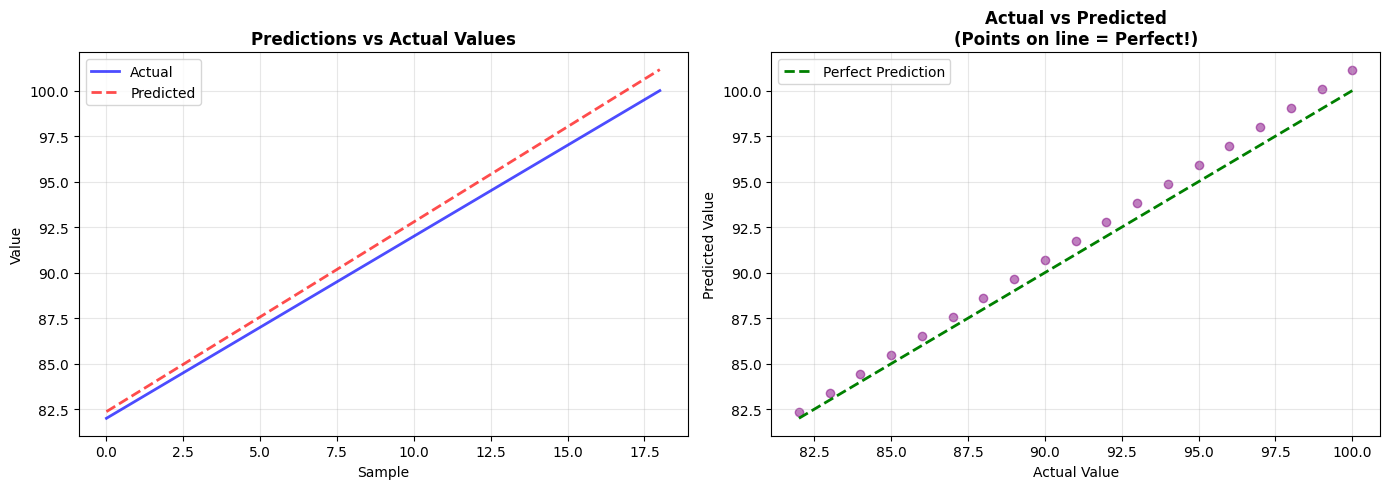


💡 If the LSTM learned perfectly, the dots would be on the green line!


In [10]:
# ============================================================================
# 📊 VISUALIZE PREDICTIONS
# ============================================================================

# Predict on test set
y_pred = model.predict(X_test, verbose=0).flatten()

# Denormalize
y_test_actual = y_test * max_value
y_pred_actual = y_pred * max_value

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Predictions vs Actual
axes[0].plot(y_test_actual, 'b-', label='Actual', linewidth=2, alpha=0.7)
axes[0].plot(y_pred_actual, 'r--', label='Predicted', linewidth=2, alpha=0.7)
axes[0].set_title('Predictions vs Actual Values', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sample')
axes[0].set_ylabel('Value')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Scatter plot (perfect prediction = diagonal line)
axes[1].scatter(y_test_actual, y_pred_actual, alpha=0.5, c='purple')
axes[1].plot([y_test_actual.min(), y_test_actual.max()],
             [y_test_actual.min(), y_test_actual.max()],
             'g--', linewidth=2, label='Perfect Prediction')
axes[1].set_title('Actual vs Predicted\n(Points on line = Perfect!)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Actual Value')
axes[1].set_ylabel('Predicted Value')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 If the LSTM learned perfectly, the dots would be on the green line!")

---
## 🔮 Step 7: Generate a Sequence!

Let's have the LSTM generate numbers on its own!

🔮 LSTM Sequence Generation!

Seed: [1, 2, 3, 4, 5]
Generated: ['6.4', '7.4', '8.4', '9.5', '10.5', '11.5', '12.5', '13.5', '14.5', '15.5']

Expected: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


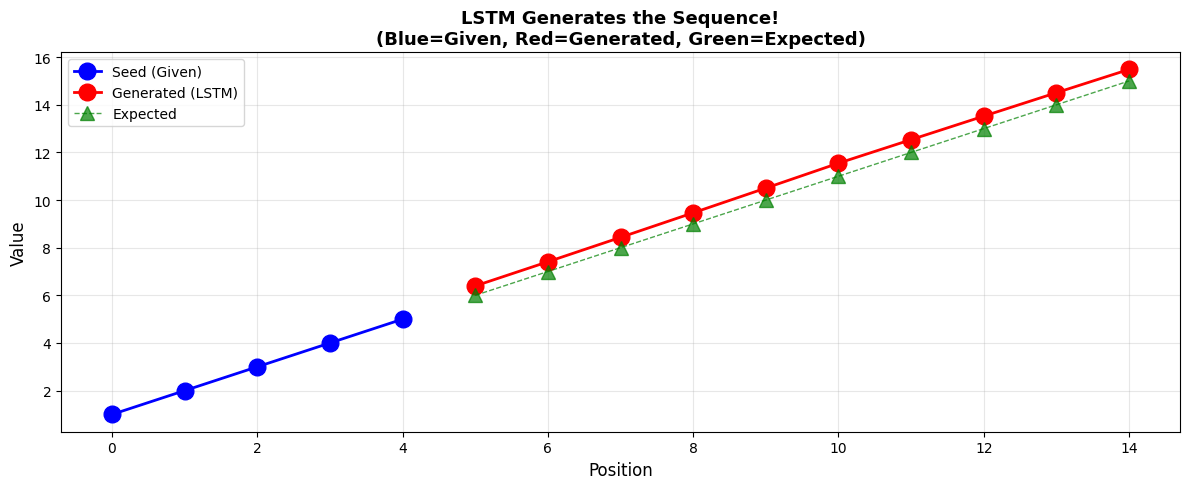

In [11]:
# ============================================================================
# 🔮 GENERATE SEQUENCE WITH LSTM
# ============================================================================

def generate_sequence(model, seed_sequence, num_predictions, max_val):
    """
    Generate new numbers using the LSTM.

    seed_sequence: Starting numbers (e.g., [1,2,3,4,5])
    num_predictions: How many new numbers to generate
    """
    current_seq = list(seed_sequence)
    predictions = []

    for _ in range(num_predictions):
        # Take last WINDOW_SIZE numbers
        input_seq = np.array(current_seq[-WINDOW_SIZE:]) / max_val
        input_seq = input_seq.reshape(1, WINDOW_SIZE, 1)

        # Predict next number
        pred = model.predict(input_seq, verbose=0)[0][0] * max_val

        # Add to sequence
        predictions.append(pred)
        current_seq.append(pred)

    return predictions


# Start with [1,2,3,4,5] and generate 10 more numbers
seed = [1, 2, 3, 4, 5]
generated = generate_sequence(model, seed, 10, max_value)

print("🔮 LSTM Sequence Generation!\n")
print(f"Seed: {seed}")
print(f"Generated: {[f'{x:.1f}' for x in generated]}")
print(f"\nExpected: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15]")

# Visualize
fig, ax = plt.subplots(figsize=(12, 5))

# Plot seed
ax.plot(range(len(seed)), seed, 'bo-', markersize=12, linewidth=2, label='Seed (Given)')

# Plot generated
gen_x = range(len(seed), len(seed) + len(generated))
ax.plot(gen_x, generated, 'ro-', markersize=12, linewidth=2, label='Generated (LSTM)')

# Plot expected
expected = list(range(6, 16))
ax.plot(gen_x, expected, 'g^--', markersize=10, linewidth=1, alpha=0.7, label='Expected')

ax.set_xlabel('Position', fontsize=12)
ax.set_ylabel('Value', fontsize=12)
ax.set_title('LSTM Generates the Sequence!\n(Blue=Given, Red=Generated, Green=Expected)',
             fontsize=13, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 🎯 Step 8: Try a Harder Pattern - Count by 2s!

Let's see if LSTM can learn: 2, 4, 6, 8, 10...

In [12]:
# ============================================================================
# 🎯 TRAIN ON COUNT BY 2s: 2, 4, 6, 8, 10...
# ============================================================================

print("🎯 Training LSTM on: 2, 4, 6, 8, 10, ...\n")

# Create sequence
seq_by2 = create_counting_sequence(2, 2, 100)  # 2, 4, 6, ..., 200
max_val_2 = seq_by2.max()
seq_by2_norm = seq_by2 / max_val_2

# Prepare data
X2, y2 = prepare_sequences(seq_by2_norm, WINDOW_SIZE)
split2 = int(len(X2) * 0.8)
X2_train, X2_test = X2[:split2], X2[split2:]
y2_train, y2_test = y2[:split2], y2[split2:]

# Build new model
inputs2 = keras.Input(shape=(WINDOW_SIZE, 1))
x2 = layers.LSTM(50)(inputs2)
x2 = layers.Dense(25, activation='relu')(x2)
outputs2 = layers.Dense(1)(x2)
model2 = keras.Model(inputs=inputs2, outputs=outputs2)
model2.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train
history2 = model2.fit(X2_train, y2_train, epochs=100, batch_size=16,
                      validation_data=(X2_test, y2_test), verbose=0)

print("✅ Training complete!\n")

# Test
test_seqs_2 = [
    [2, 4, 6, 8, 10],       # Should predict 12
    [20, 22, 24, 26, 28],   # Should predict 30
    [100, 102, 104, 106, 108], # Should predict 110
]

print("📝 Predictions:\n")
print(f"{'Input Sequence':<30} {'Expected':>10} {'Predicted':>12}")
print("=" * 55)

for seq in test_seqs_2:
    seq_norm = np.array(seq) / max_val_2
    seq_input = seq_norm.reshape(1, WINDOW_SIZE, 1)
    pred = model2.predict(seq_input, verbose=0)[0][0] * max_val_2
    expected = seq[-1] + 2
    print(f"{str(seq):<30} {expected:>10} {pred:>12.2f}")

# Generate sequence
seed2 = [2, 4, 6, 8, 10]
generated2 = generate_sequence(model2, seed2, 10, max_val_2)

print(f"\n🔮 Generation:")
print(f"   Seed: {seed2}")
print(f"   Generated: {[f'{x:.1f}' for x in generated2]}")
print(f"   Expected: {list(range(12, 32, 2))}")

🎯 Training LSTM on: 2, 4, 6, 8, 10, ...



✅ Training complete!

📝 Predictions:

Input Sequence                   Expected    Predicted
[2, 4, 6, 8, 10]                       12        13.89
[20, 22, 24, 26, 28]                   30        30.53


[100, 102, 104, 106, 108]             110       109.65



🔮 Generation:
   Seed: [2, 4, 6, 8, 10]
   Generated: ['13.9', '16.0', '18.2', '20.5', '22.8', '25.2', '27.3', '29.4', '31.5', '33.5']
   Expected: [12, 14, 16, 18, 20, 22, 24, 26, 28, 30]


---
## 🎮 Step 9: Your Turn! Try Your Own Sequences

Change the values below to test different patterns!

🎮 YOUR CUSTOM SEQUENCE TRAINER

✏️ Custom Sequence
   Your pattern: [1, 2, 4, 7, 11, 16, 22, 29]...
   Total numbers: 26

📦 Data prepared:
   Sequence length: 26
   Training samples: 16
   Testing samples: 5

⏳ Training LSTM on Custom Sequence...
   (Training for 150 epochs)
Epoch 1/150


1/1 - 2s - 2s/step - loss: 0.1160 - mae: 0.2874 - val_loss: 0.6889 - val_mae: 0.8240


Epoch 2/150


1/1 - 0s - 67ms/step - loss: 0.1118 - mae: 0.2810 - val_loss: 0.6691 - val_mae: 0.8120


Epoch 3/150


1/1 - 0s - 65ms/step - loss: 0.1070 - mae: 0.2728 - val_loss: 0.6459 - val_mae: 0.7978


... (294 outputs left out)

✅ Training complete!



🧪 TESTING YOUR LSTM

Input (5 numbers)                         Actual Next    Predicted      Error
------------------------------------------------------------------------------


['1', '2', '4', '7', '11']                       16.0         26.4 ❌  64.8%
['22', '29', '37', '46', '56']                   67.0         63.2 ⚠️   5.7%
['92', '106', '121', '137', '154']              172.0        172.4 ✅   0.2%

🔮 GENERATE NEW NUMBERS

🌱 Starting seed: ['16', '22', '29', '37', '46']
📝 LSTM will predict the next 8 numbers...



   Position   Generated       Actual          Match?    
   --------------------------------------------------
   1          53.7            56.0            ✅         
   2          63.0            67.0            ⚠️        
   3          73.3            79.0            ⚠️        
   4          84.6            92.0            ⚠️        
   5          96.7            106.0           ⚠️        
   6          109.5           121.0           ⚠️        
   7          124.1           137.0           ⚠️        
   8          140.3           154.0           ⚠️        


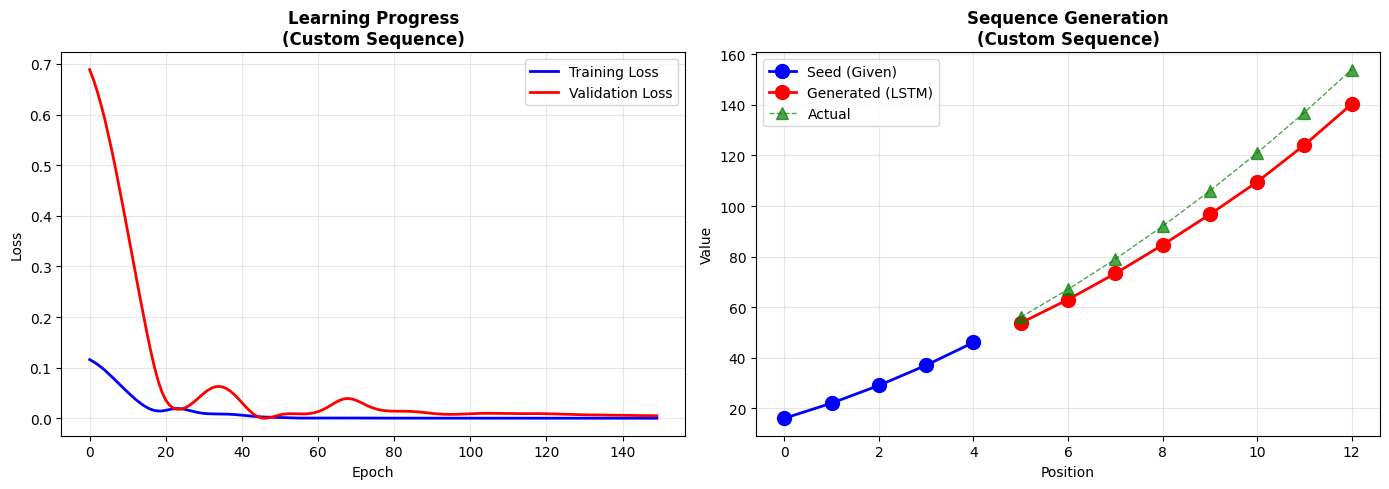


💡 THINGS TO TRY:

   📐 AP Examples:
      • Odd numbers: AP_START=1, AP_STEP=2
      • Multiples of 7: AP_START=7, AP_STEP=7

   📐 GP Examples:
      • Powers of 2: GP_START=1, GP_RATIO=2 → 1,2,4,8,16...
      • Powers of 3: GP_START=1, GP_RATIO=3 → 1,3,9,27,81...

   ✏️ CUSTOM Examples (copy & paste into CUSTOM_SEQUENCE):

      • Fibonacci (add last two numbers):
        [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610,
         987, 1597, 2584, 4181, 6765, 10946, 17711, 28657, 46368]

      • Prime Numbers:
        [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47,
         53, 59, 61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107]

      • Triangular Numbers (1, 1+2, 1+2+3, ...):
        [1, 3, 6, 10, 15, 21, 28, 36, 45, 55, 66, 78, 91, 105, 120,
         136, 153, 171, 190, 210, 231, 253, 276, 300, 325, 351]

      • Square Numbers (1², 2², 3², ...):
        [1, 4, 9, 16, 25, 36, 49, 64, 81, 100, 121, 144, 169, 196,
         225, 256, 289, 324, 361, 400, 441, 484, 529,

In [13]:
# ============================================================================
# 🎮 TRY YOUR OWN SEQUENCE! - Interactive Playground
# ============================================================================

# ╔════════════════════════════════════════════════════════════════════════════╗
# ║  🎯 CHOOSE YOUR PATTERN TYPE!                                              ║
# ║                                                                            ║
# ║  Options:                                                                  ║
# ║    "AP"     = Arithmetic Progression (add same number each time)          ║
# ║              Examples: 2,4,6,8 or 5,10,15,20 or 3,7,11,15                 ║
# ║                                                                            ║
# ║    "GP"     = Geometric Progression (multiply by same number each time)   ║
# ║              Examples: 2,4,8,16 or 3,9,27,81 or 5,10,20,40               ║
# ║                                                                            ║
# ║    "CUSTOM" = Type your own sequence!                                      ║
# ║              Examples: Fibonacci, primes, or any pattern you like!        ║
# ╚════════════════════════════════════════════════════════════════════════════╝

# ===== 👇 CHOOSE YOUR SETTINGS! 👇 =====

PATTERN_TYPE = "CUSTOM"  # Choose: "AP", "GP", or "CUSTOM"

# ----- For AP (Arithmetic Progression) -----
AP_START = 5         # Starting number
AP_STEP = 5          # Add this much each time (common difference)

# ----- For GP (Geometric Progression) -----
GP_START = 2         # Starting number
GP_RATIO = 2         # Multiply by this each time (common ratio)

# ----- For CUSTOM sequence -----
# Type your own numbers! (at least 20 numbers recommended)
CUSTOM_SEQUENCE = [1, 2, 4, 7, 11, 16, 22, 29, 37, 46, 56, 67, 79, 92, 106,
         121, 137, 154, 172, 191, 211, 232, 254, 277, 301, 326]  # add 1, then 2, then 3... (lazy caterer numbers)

# ==========================================

print("=" * 60)
print("🎮 YOUR CUSTOM SEQUENCE TRAINER")
print("=" * 60)

# ============================================================================
# 📊 CREATE THE SEQUENCE
# ============================================================================

if PATTERN_TYPE.upper() == "AP":
    # Arithmetic Progression: a, a+d, a+2d, a+3d, ...
    my_seq = [AP_START + AP_STEP * i for i in range(100)]
    pattern_name = f"AP (start={AP_START}, step=+{AP_STEP})"
    step_for_check = AP_STEP
    print(f"\n📐 Arithmetic Progression (AP)")
    print(f"   Formula: a + (n-1)d where a={AP_START}, d={AP_STEP}")
    print(f"   Pattern: {my_seq[0]}, {my_seq[1]}, {my_seq[2]}, {my_seq[3]}, {my_seq[4]}, {my_seq[5]}, {my_seq[6]}, {my_seq[7]}...")

elif PATTERN_TYPE.upper() == "GP":
    # Geometric Progression: a, ar, ar², ar³, ...
    my_seq = [GP_START * (GP_RATIO ** i) for i in range(30)]  # Fewer terms (GP grows fast!)
    pattern_name = f"GP (start={GP_START}, ratio=×{GP_RATIO})"
    step_for_check = None  # GP doesn't have fixed step
    print(f"\n📐 Geometric Progression (GP)")
    print(f"   Formula: a × r^(n-1) where a={GP_START}, r={GP_RATIO}")
    print(f"   Pattern: {my_seq[0]}, {my_seq[1]}, {my_seq[2]}, {my_seq[3]}, {my_seq[4]}, {my_seq[5]}, {my_seq[6]}, {my_seq[7]}...")

elif PATTERN_TYPE.upper() == "CUSTOM":
    my_seq = CUSTOM_SEQUENCE.copy()
    pattern_name = "Custom Sequence"
    step_for_check = None
    print(f"\n✏️ Custom Sequence")
    print(f"   Your pattern: {my_seq[:8]}...")
    print(f"   Total numbers: {len(my_seq)}")

else:
    print("❌ Invalid PATTERN_TYPE! Use 'AP', 'GP', or 'CUSTOM'")
    my_seq = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]  # Default
    pattern_name = "Default"
    step_for_check = 1

# Convert to numpy array and ensure float type
my_seq = np.array(my_seq, dtype=np.float64)

# Check minimum length
if len(my_seq) < 10:
    print("⚠️ Warning: Sequence too short! Need at least 10 numbers for good training.")

# Normalize (scale to 0-1 range)
my_max = my_seq.max()
my_min = my_seq.min()
my_seq_norm = (my_seq - my_min) / (my_max - my_min) if my_max != my_min else my_seq / my_max

# Prepare training data
X_my, y_my = prepare_sequences(my_seq_norm, WINDOW_SIZE)

# Split into training and testing
split_my = int(len(X_my) * 0.8)
X_my_train, X_my_test = X_my[:split_my], X_my[split_my:]
y_my_train, y_my_test = y_my[:split_my], y_my[split_my:]

print(f"\n📦 Data prepared:")
print(f"   Sequence length: {len(my_seq)}")
print(f"   Training samples: {len(X_my_train)}")
print(f"   Testing samples: {len(X_my_test)}")

# Build a fresh LSTM model with 2 LSTM layers
inputs_my = keras.Input(shape=(WINDOW_SIZE, 1))
x_my = layers.LSTM(64, return_sequences=True)(inputs_my)  # First LSTM layer (returns sequences for next LSTM)
x_my = layers.LSTM(32)(x_my)  # Second LSTM layer
x_my = layers.Dense(16, activation='relu')(x_my)
outputs_my = layers.Dense(1)(x_my)
model_my = keras.Model(inputs=inputs_my, outputs=outputs_my)
model_my.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train (more epochs for complex patterns)
epochs = 150 if PATTERN_TYPE.upper() in ["GP", "CUSTOM"] else 100
print(f"\n⏳ Training LSTM on {pattern_name}...")
print(f"   (Training for {epochs} epochs)")

history_my = model_my.fit(
    X_my_train, y_my_train,
    epochs=epochs,
    batch_size=16,
    validation_data=(X_my_test, y_my_test),
    verbose=2   # one line per epoch
)
print("✅ Training complete!")

# ============================================================================
# 🧪 TEST THE MODEL
# ============================================================================

print("\n" + "=" * 60)
print("🧪 TESTING YOUR LSTM")
print("=" * 60)

# Create test sequences from different parts of the range
num_samples = len(my_seq)
test_indices = [0, num_samples//4, num_samples//2]

print(f"\n{'Input (5 numbers)':<40} {'Actual Next':>12} {'Predicted':>12} {'Error':>10}")
print("-" * 78)

errors = []
for start_idx in test_indices:
    if start_idx + WINDOW_SIZE + 1 > len(my_seq):
        continue

    # Get test sequence - convert to Python list of floats
    test_seq = [float(x) for x in my_seq[start_idx:start_idx + WINDOW_SIZE]]
    actual_next = float(my_seq[start_idx + WINDOW_SIZE])

    # Prepare input
    seq_norm = (np.array(test_seq) - my_min) / (my_max - my_min) if my_max != my_min else np.array(test_seq) / my_max
    seq_input = seq_norm.reshape(1, WINDOW_SIZE, 1)

    # Predict
    pred_norm = model_my.predict(seq_input, verbose=0)[0][0]
    pred = pred_norm * (my_max - my_min) + my_min if my_max != my_min else pred_norm * my_max

    # Calculate error
    error = abs(pred - actual_next)
    error_pct = (error / actual_next * 100) if actual_next != 0 else 0
    errors.append(error_pct)

    # Format for display
    test_seq_str = [f"{x:.0f}" if x == int(x) else f"{x:.1f}" for x in test_seq]
    status = "✅" if error_pct < 5 else "⚠️" if error_pct < 15 else "❌"

    print(f"{str(test_seq_str):<40} {actual_next:>12.1f} {pred:>12.1f} {status} {error_pct:>5.1f}%")

avg_error = sum(errors) / len(errors) if errors else 0

# ============================================================================
# 🔮 GENERATE NEW NUMBERS
# ============================================================================

print("\n" + "=" * 60)
print("🔮 GENERATE NEW NUMBERS")
print("=" * 60)

# Use a seed from near the beginning
seed_start = min(5, len(my_seq) - WINDOW_SIZE - 10)
seed_seq = [float(x) for x in my_seq[seed_start:seed_start + WINDOW_SIZE]]

print(f"\n🌱 Starting seed: {[f'{x:.0f}' if x == int(x) else f'{x:.1f}' for x in seed_seq]}")
print(f"📝 LSTM will predict the next 8 numbers...\n")

# Generate sequence
generated = []
current_seq = seed_seq.copy()

for i in range(8):
    # Prepare input
    seq_norm = (np.array(current_seq[-WINDOW_SIZE:]) - my_min) / (my_max - my_min) if my_max != my_min else np.array(current_seq[-WINDOW_SIZE:]) / my_max
    seq_input = seq_norm.reshape(1, WINDOW_SIZE, 1)

    # Predict next number
    pred_norm = model_my.predict(seq_input, verbose=0)[0][0]
    next_num = pred_norm * (my_max - my_min) + my_min if my_max != my_min else pred_norm * my_max
    generated.append(float(next_num))
    current_seq.append(float(next_num))

# Get actual values if they exist
actual_next_values = []
for i in range(8):
    idx = seed_start + WINDOW_SIZE + i
    if idx < len(my_seq):
        actual_next_values.append(float(my_seq[idx]))
    else:
        actual_next_values.append(None)

# Display results
print(f"   {'Position':<10} {'Generated':<15} {'Actual':<15} {'Match?':<10}")
print(f"   {'-'*50}")
for i, (gen, act) in enumerate(zip(generated, actual_next_values)):
    gen_str = f"{gen:.1f}"
    if act is not None:
        act_str = f"{act:.1f}"
        match = "✅" if abs(gen - act) / act < 0.05 else "⚠️" if abs(gen - act) / act < 0.15 else "❌"
    else:
        act_str = "N/A"
        match = "🔮"
    print(f"   {i+1:<10} {gen_str:<15} {act_str:<15} {match:<10}")

# ============================================================================
# 📊 VISUALIZE RESULTS
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Training history
axes[0].plot(history_my.history['loss'], 'b-', label='Training Loss', linewidth=2)
axes[0].plot(history_my.history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
axes[0].set_title(f'Learning Progress\n({pattern_name})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Generated vs Expected
x_seed = range(len(seed_seq))
x_gen = range(len(seed_seq), len(seed_seq) + len(generated))

axes[1].plot(x_seed, seed_seq, 'bo-', markersize=10, linewidth=2, label='Seed (Given)')
axes[1].plot(x_gen, generated, 'ro-', markersize=10, linewidth=2, label='Generated (LSTM)')

# Plot actual if available
actual_to_plot = [a for a in actual_next_values if a is not None]
if actual_to_plot:
    x_actual = range(len(seed_seq), len(seed_seq) + len(actual_to_plot))
    axes[1].plot(x_actual, actual_to_plot, 'g^--', markersize=8, linewidth=1, alpha=0.7, label='Actual')

axes[1].set_title(f'Sequence Generation\n({pattern_name})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Position')
axes[1].set_ylabel('Value')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================================
# 📋 FINAL SUMMARY
# ============================================================================

print("\n" + "=" * 60)
print("💡 THINGS TO TRY:")
print("=" * 60)
print("""
   📐 AP Examples:
      • Odd numbers: AP_START=1, AP_STEP=2
      • Multiples of 7: AP_START=7, AP_STEP=7

   📐 GP Examples:
      • Powers of 2: GP_START=1, GP_RATIO=2 → 1,2,4,8,16...
      • Powers of 3: GP_START=1, GP_RATIO=3 → 1,3,9,27,81...

   ✏️ CUSTOM Examples (copy & paste into CUSTOM_SEQUENCE):

      • Fibonacci (add last two numbers):
        [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610,
         987, 1597, 2584, 4181, 6765, 10946, 17711, 28657, 46368]

      • Prime Numbers:
        [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47,
         53, 59, 61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107]

      • Triangular Numbers (1, 1+2, 1+2+3, ...):
        [1, 3, 6, 10, 15, 21, 28, 36, 45, 55, 66, 78, 91, 105, 120,
         136, 153, 171, 190, 210, 231, 253, 276, 300, 325, 351]

      • Square Numbers (1², 2², 3², ...):
        [1, 4, 9, 16, 25, 36, 49, 64, 81, 100, 121, 144, 169, 196,
         225, 256, 289, 324, 361, 400, 441, 484, 529, 576, 625]

      • Cube Numbers (1³, 2³, 3³, ...):
        [1, 8, 27, 64, 125, 216, 343, 512, 729, 1000, 1331, 1728,
         2197, 2744, 3375, 4096, 4913, 5832, 6859, 8000, 9261]

      • Powers of 2:
        [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096,
         8192, 16384, 32768, 65536, 131072, 262144, 524288]

      • Factorials (1!, 2!, 3!, ...):
        [1, 2, 6, 24, 120, 720, 5040, 40320, 362880, 3628800,
         39916800, 479001600, 6227020800, 87178291200]

      • Catalan Numbers:
        [1, 1, 2, 5, 14, 42, 132, 429, 1430, 4862, 16796, 58786,
         208012, 742900, 2674440, 9694845, 35357670, 129644790]

      • Pentagonal Numbers:
        [1, 5, 12, 22, 35, 51, 70, 92, 117, 145, 176, 210, 247,
         287, 330, 376, 425, 477, 532, 590, 651, 715, 782, 852]

      • Lazy Caterer (max pizza slices with n cuts):
        [1, 2, 4, 7, 11, 16, 22, 29, 37, 46, 56, 67, 79, 92, 106,
         121, 137, 154, 172, 191, 211, 232, 254, 277, 301, 326]
""")

---
## 🧠 Step 10: See the LSTM's Memory!

Let's peek inside the LSTM to see how it "remembers"!

🧠 LSTM Memory Visualization

Input sequence: [1, 2, 3, 4, 5]

Hidden state shape: (1, 5, 50)
  → At each timestep, LSTM has 50 'memory values'


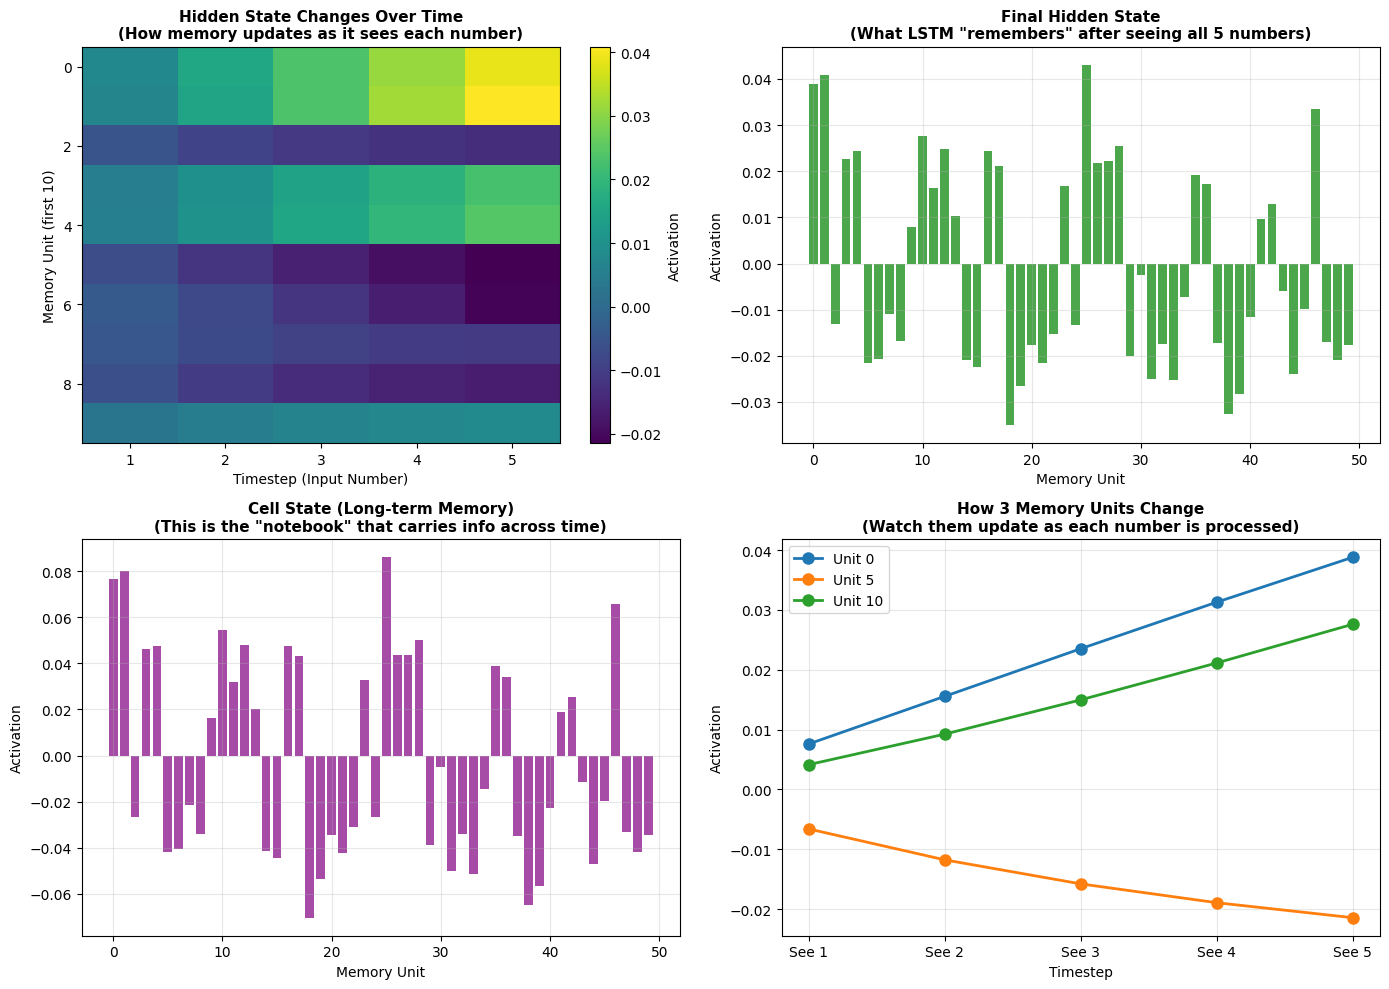


💡 Key Insights:
   • Each 'memory unit' stores different information
   • The hidden state UPDATES after seeing each number
   • Cell state = long-term memory (the notebook!)
   • This is how LSTM 'remembers' the pattern!


In [14]:
# ============================================================================
# 🧠 VISUALIZE LSTM MEMORY (Hidden States)
# ============================================================================

# Create a model that outputs the LSTM hidden state
# We need to rebuild with return_sequences=True to see all timesteps

inputs_viz = keras.Input(shape=(WINDOW_SIZE, 1))
lstm_layer = layers.LSTM(50, return_sequences=True,
                         return_state=True, name='lstm_viz')
lstm_output, final_h, final_c = lstm_layer(inputs_viz)
x_viz = layers.Dense(25, activation='relu')(final_h)
outputs_viz = layers.Dense(1)(x_viz)

# Model for prediction
model_viz = keras.Model(inputs=inputs_viz, outputs=outputs_viz)

# Model for seeing hidden states
state_model = keras.Model(inputs=inputs_viz, outputs=[lstm_output, final_h, final_c])

# Train briefly
model_viz.compile(optimizer='adam', loss='mse')
model_viz.fit(X_train, y_train, epochs=50, batch_size=16, verbose=0)

# Get hidden states for a sequence
test_input = np.array([1, 2, 3, 4, 5]) / max_value
test_input = test_input.reshape(1, 5, 1)

all_hidden, final_hidden, cell_state = state_model.predict(test_input, verbose=0)

print("🧠 LSTM Memory Visualization\n")
print(f"Input sequence: [1, 2, 3, 4, 5]")
print(f"\nHidden state shape: {all_hidden.shape}")
print(f"  → At each timestep, LSTM has 50 'memory values'")

# Visualize
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Hidden states over time (first 10 units)
im1 = axes[0, 0].imshow(all_hidden[0, :, :10].T, aspect='auto', cmap='viridis')
axes[0, 0].set_xlabel('Timestep (Input Number)')
axes[0, 0].set_ylabel('Memory Unit (first 10)')
axes[0, 0].set_xticks(range(5))
axes[0, 0].set_xticklabels(['1', '2', '3', '4', '5'])
axes[0, 0].set_title('Hidden State Changes Over Time\n(How memory updates as it sees each number)',
                     fontsize=11, fontweight='bold')
plt.colorbar(im1, ax=axes[0, 0], label='Activation')

# Plot 2: Final hidden state
axes[0, 1].bar(range(50), final_hidden[0], color='green', alpha=0.7)
axes[0, 1].set_xlabel('Memory Unit')
axes[0, 1].set_ylabel('Activation')
axes[0, 1].set_title('Final Hidden State\n(What LSTM "remembers" after seeing all 5 numbers)',
                     fontsize=11, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Cell state (long-term memory)
axes[1, 0].bar(range(50), cell_state[0], color='purple', alpha=0.7)
axes[1, 0].set_xlabel('Memory Unit')
axes[1, 0].set_ylabel('Activation')
axes[1, 0].set_title('Cell State (Long-term Memory)\n(This is the "notebook" that carries info across time)',
                     fontsize=11, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Memory evolution for 3 units
for i in [0, 5, 10]:
    axes[1, 1].plot(all_hidden[0, :, i], 'o-', label=f'Unit {i}', linewidth=2, markersize=8)
axes[1, 1].set_xlabel('Timestep')
axes[1, 1].set_ylabel('Activation')
axes[1, 1].set_xticks(range(5))
axes[1, 1].set_xticklabels(['See 1', 'See 2', 'See 3', 'See 4', 'See 5'])
axes[1, 1].set_title('How 3 Memory Units Change\n(Watch them update as each number is processed)',
                     fontsize=11, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 Key Insights:")
print("   • Each 'memory unit' stores different information")
print("   • The hidden state UPDATES after seeing each number")
print("   • Cell state = long-term memory (the notebook!)")
print("   • This is how LSTM 'remembers' the pattern!")

---
## 🎓 Summary: What We Learned!

### 🧠 How LSTM Remembers:

| Component | What It Does | Analogy |
|-----------|-------------|----------|
| **Cell State** | Long-term memory | Your notebook 📓 |
| **Hidden State** | Short-term memory | What you're thinking right now 💭 |
| **Forget Gate** | Decides what to erase | "Is this still useful?" 🗑️ |
| **Input Gate** | Decides what to write | "Should I remember this?" ✍️ |
| **Output Gate** | Decides what to say | "What's my answer?" 🎤 |

### 🔑 Key Takeaways:

1. **Regular networks forget** - LSTM remembers!
2. **Gates control memory** - like doors deciding what info comes in/out
3. **Cell state is the notebook** - carries information through time
4. **Practice helps, but test fairly** - always check on numbers the model has NOT seen, and compare with a simple rule

### 🚀 What's Next?

LSTMs can do amazing things:
- 📝 Write stories and poems
- 🎵 Compose music
- 🌐 Translate languages
- 📈 Forecast the weather and how much electricity a city will use
- 🗣️ Understand speech

---

In [15]:
print("🎉 Congratulations! You've learned how LSTM remembers!")
print("")
print("📚 Remember:")
print("   🧠 LSTM = Long Short-Term Memory")
print("   📓 It's like a student with a notebook")
print("   🚪 Gates control what to remember/forget")
print("   🔢 It can learn number patterns!")
print("")
print("🎮 Try This:")
print("   • Change PATTERN_TYPE, AP_START and AP_STEP in Step 9")
print("   • Try Fibonacci sequence (harder!)")
print("   • Make the WINDOW_SIZE bigger or smaller")
print("   • Add more LSTM units (change 50 to 100)")
print("")
print("🌟 You're now an LSTM expert! 🌟")

🎉 Congratulations! You've learned how LSTM remembers!

📚 Remember:
   🧠 LSTM = Long Short-Term Memory
   📓 It's like a student with a notebook
   🚪 Gates control what to remember/forget
   🔢 It can learn number patterns!

🎮 Try This:
   • Change PATTERN_TYPE, AP_START and AP_STEP in Step 9
   • Try Fibonacci sequence (harder!)
   • Make the WINDOW_SIZE bigger or smaller
   • Add more LSTM units (change 50 to 100)

🌟 You're now an LSTM expert! 🌟
